# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 7: Convergence Analysis of a Genetic Algorithm**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Yashvi Shivhare* |
| **Enrollment No.** | *2023BTCSE021* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

### 2. Theory: Tracking Evolutionary Progress

Monitoring **Best**, **Mean**, and **Min** fitness across generations reveals how quickly the population discovers high-fitness regions and how diversity narrows over time.

### 3. Step 1: Recording & Plotting Convergence Metrics

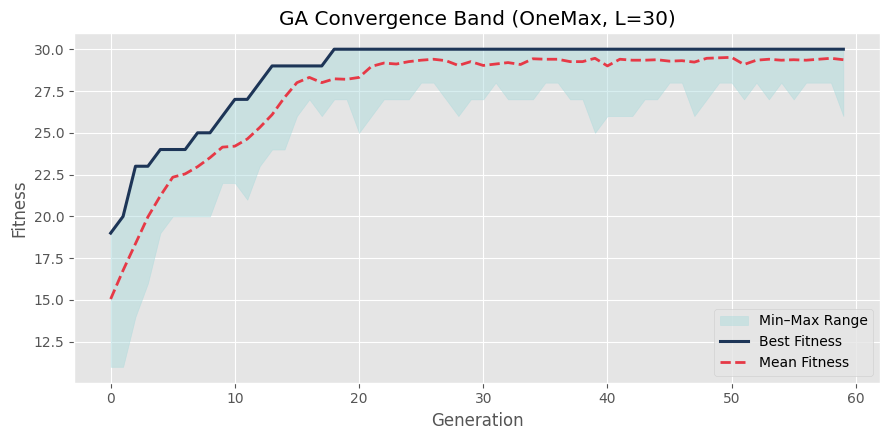

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(707)
plt.style.use('ggplot')

pop_size, chrom_len, gens = 35, 30, 60
pc, pm = 0.8, 0.02
pop = np.random.randint(0, 2, size=(pop_size, chrom_len))

best_h, mean_h, min_h = [], [], []
for _ in range(gens):
    fit = np.sum(pop, axis=1)
    best_h.append(np.max(fit))
    mean_h.append(np.mean(fit))
    min_h.append(np.min(fit))

    next_pop = [pop[np.argmax(fit)].copy()]
    while len(next_pop) < pop_size:
        c1 = np.random.choice(pop_size, 3, replace=False)
        p1 = pop[c1[np.argmax(fit[c1])]]
        c2 = np.random.choice(pop_size, 3, replace=False)
        p2 = pop[c2[np.argmax(fit[c2])]]
        if np.random.rand() < pc:
            pt = np.random.randint(1, chrom_len)
            o1 = np.concatenate([p1[:pt], p2[pt:]])
            o2 = np.concatenate([p2[:pt], p1[pt:]])
        else:
            o1, o2 = p1.copy(), p2.copy()
        for o in (o1, o2):
            m = np.random.rand(chrom_len) < pm
            o[m] = 1 - o[m]
            if len(next_pop) < pop_size:
                next_pop.append(o)
    pop = np.array(next_pop)

x = np.arange(gens)
plt.figure(figsize=(9, 4.5))
plt.fill_between(x, min_h, best_h, color='#a8dadc', alpha=0.45, label='Min–Max Range')
plt.plot(x, best_h, color='#1d3557', linewidth=2.2, label='Best Fitness')
plt.plot(x, mean_h, color='#e63946', linewidth=2, linestyle='--', label='Mean Fitness')
plt.title("GA Convergence Band (OneMax, L=30)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.tight_layout()
plt.show()

### 4. Conclusion
The shaded min–max convergence band clearly illustrates rapid early exploration followed by steady convergence of the population mean toward the optimum.